# INFORME TÉCNICO: EVALUACIÓN PARCIAL N°2
## Desarrollo de un Agente Funcional con Arquitectura Jerárquica

**Institución:** DuocUC
**Asignatura:** Ingeniería de Soluciones con IA
**Sigla:** ISY0101
**Evaluación:** Parcial N°2 (35% de ponderación)
**Modalidad:** Grupal

---

### Integrantes del Equipo
*   **David Santibáñez**
*   **Benjamin Castro**
*   **Luis Quijada**

**Docente:** Rodrigo Pablo Seguel Breskovic
**Sección:** 012-V
**Fecha de Entrega:** Semana 13 - 23/10/2026

---

### Contexto de la Solución
**Empresa Simulada:** TechCorp SpA
**Caso de Uso:** Agente de Soporte Técnico Nivel 1 (Mesa de Ayuda TI)
**Repositorio GitHub:** https://github.com/david17cor/ing-sol-ia-ev2.git

---

### Declaración de Uso de Inteligencia Artificial
En conformidad con las directrices de la asignatura, declaramos que se utilizaron las siguientes herramientas de Inteligencia Artificial, citadas en la sección de Referencias según bibliotecas.duoc.cl/ia:
*   **DeepSeek:** apoyo en la redacción de código base, depuración de errores (debugging) y estructuración de diagramas.
*   **Claude (Anthropic):** revisión del notebook contra la pauta de evaluación, corrección de código (escalamiento, uso de prioridad y CMDB, escenarios de prueba) y redacción del README.

Todo el contenido generado con IA fue revisado y validado por el equipo. Las ideas, la arquitectura jerárquica, el análisis del caso de negocio, las justificaciones técnicas y las conclusiones son de autoría propia del equipo.

# 1. Contexto Organizacional y Problemática

### 1.1 La Empresa: TechCorp SpA
TechCorp SpA es una empresa ficticia de servicios tecnológicos B2B con 450 empleados distribuidos en tres sedes (Santiago, Valparaíso y Concepción). Su Mesa de Ayuda TI (Service Desk) es el punto único de contacto para incidencias tecnológicas.

### 1.2 Situación Actual (El Problema)
Actualmente, el equipo de soporte Nivel 1 enfrenta una crisis operativa:
*   **Sobrecarga:** Reciben entre 80 y 120 tickets diarios, clasificados manualmente.
*   **Lentitud:** El tiempo de primera respuesta promedia los **45 minutos**.
*   **Repetición:** El 35% de los tickets corresponden a problemas recurrentes (VPN, contraseñas, impresoras) que no requieren un análisis profundo.
*   **Pérdida de SLA:** Los tickets críticos se mezclan con los de baja prioridad, provocando incumplimiento de los Acuerdos de Nivel de Servicio (SLA).
*   **Amnesia Organizacional:** No existe una memoria histórica; cada incidente se resuelve desde cero, incluso si se solucionó ayer.

### 1.3 Objetivo del Proyecto
Automatizar la primera línea de soporte mediante un Agente de IA que sea capaz de:
1.  **Clasificar** tickets autónomamente por categoría y prioridad.
2.  **Resolver** problemas comunes consultando una Base de Conocimientos (RAG).
3.  **Escalar** a Nivel 2 solo aquellos casos complejos o críticos.
4.  **Recordar** interacciones pasadas para mantener el contexto de la conversación.

---

# 2. Solución Ofrecida: Arquitectura Jerárquica Multi-Agente

Para evitar que un solo modelo de lenguaje cometa errores o se sature, se diseñó una **arquitectura jerárquica** utilizando el framework **LangGraph**. En lugar de un solo agente, el sistema cuenta con un "equipo" de agentes especializados coordinados por un Supervisor.

### 2.1 Componentes del Sistema (Justificación de Diseño)

1.  **Supervisor (El Orquestador):** Es el cerebro del flujo. No resuelve tickets, sino que evalúa el estado de la tarea y decide qué sub-agente debe actuar a continuación (Clasificar -> Resolver -> Escalar -> Finalizar).
2.  **Clasificador:** Analiza el ticket entrante, determina la categoría (VPN, Hardware, Accesos, Impresoras, Otros) y le asigna una prioridad (Alta, Media, Baja) según criterios explícitos de impacto.
3.  **Resolver N1:** Consulta la CMDB para conocer el equipo del usuario, crea el ticket con la prioridad asignada y busca en la base de conocimientos (RAG). Con esa información, el LLM **decide qué herramienta ejecutar**: `notificar_usuario` (si la solución aplica al problema y al equipo) o `escalar_n2` (si no aplica). Antes de consultar al LLM se aplican dos reglas: los casos con riesgo físico (humo, fuego, chispas) se escalan siempre, y si el usuario vuelve al mismo ticket porque la solución no funcionó, el caso se escala.
4.  **Escalador:** Si el Resolver determina que el problema es físico, crítico o no está en la base de conocimientos, el Escalador toma el control: el LLM redacta un resumen técnico para N2 a partir del historial del ticket, se deriva el caso y se notifica al usuario con el SLA correspondiente. Al terminar, el estado queda en `escalado_n2` y el Supervisor cierra el flujo.

### 2.2 Herramientas (Tools) Implementadas
El agente no solo "chatea", sino que tiene autonomía para modificar sistemas (cumpliendo el IL2.1):
*   `consultar_cmdb(usuario)`: Verifica qué equipo (IP, modelo) tiene asignado el usuario.
*   `buscar_kb(problema)`: Búsqueda semántica en la base de conocimientos (RAG).
*   `crear_ticket(ticket_id, descripcion, prioridad, usuario)`: Escribe en el sistema de tickets, asignando el SLA según la prioridad (Alta: 1 hora, Media: 4 horas, Baja: 24 horas).
*   `notificar_usuario(usuario, mensaje)`: Envía el correo de resolución.
*   `escalar_n2(motivo, usuario)`: Deriva el caso a ingeniería avanzada.
*   `registrar_incidente(ticket_id, resumen)`: Guarda el resultado de cada ticket cerrado en ChromaDB, para que casos futuros lo recuperen.

### 2.3 Memoria del Agente (IL2.2)
*   **Memoria a Corto Plazo:** Implementada a través del estado del grafo (`AgentState`) persistido con `MemorySaver`, usando el ID del ticket como `thread_id`. Permite que el agente recuerde el problema original, la clasificación, la solución entregada y el número de intentos cuando el usuario vuelve a escribir en el mismo ticket (ver Escenario B).
*   **Memoria a Largo Plazo:** Implementada mediante **ChromaDB** (Vector Store, similitud coseno) y Embeddings de HuggingFace (`intfloat/multilingual-e5-small`). Contiene los manuales de soporte (KB) y los incidentes históricos que el propio agente registra al cerrar cada ticket, de modo que un caso nuevo recupera tanto el manual como casos anteriores similares (ver Escenario C).

### 2.4 Stack Tecnológico (IE2)
*   **Lenguaje:** Python 3.11
*   **Framework de Agentes:** LangGraph (por su capacidad de crear flujos cíclicos y estados persistentes).
*   **LLM (Cerebro):** Groq API (Modelo `openai/gpt-oss-120b`), elegido por su baja latencia, ideal para atención al cliente.
*   **Base de Datos Vectorial:** ChromaDB (local y gratuito).
*   **Entorno de Ejecución:** Google Colab / Jupyter Notebook.

### 2.6 Planificación y Toma de Decisiones (IE5)
El agente ajusta su comportamiento según la etapa del ticket y las condiciones del entorno:

| Condición | Decisión del agente |
|---|---|
| Llegan varios tickets a la vez | El planificador clasifica la cola y la atiende en orden de prioridad (Alta → Media → Baja), no en orden de llegada |
| Ticket sin clasificar | Supervisor → Clasificador |
| Riesgo físico en el reporte | Se eleva la prioridad a Alta y se escala sin intentar solución N1 |
| La KB tiene una solución aplicable al equipo | El LLM elige `notificar_usuario` → estado `resuelto` |
| La KB no tiene solución aplicable | El LLM elige `escalar_n2` → Escalador |
| El usuario vuelve al mismo ticket | Se recupera la memoria del ticket; si ya hubo un intento N1, se escala |
| Error o respuesta inválida del LLM | Valor seguro: se escala (nunca se cierra un ticket sin solución) |

### 2.5 Diagrama de Orquestación del Sistema

A continuación, se presenta el flujo de trabajo del agente jerárquico, detallando cómo el Supervisor toma el control y deriva las tareas a los sub-agentes correspondientes según el estado del ticket:

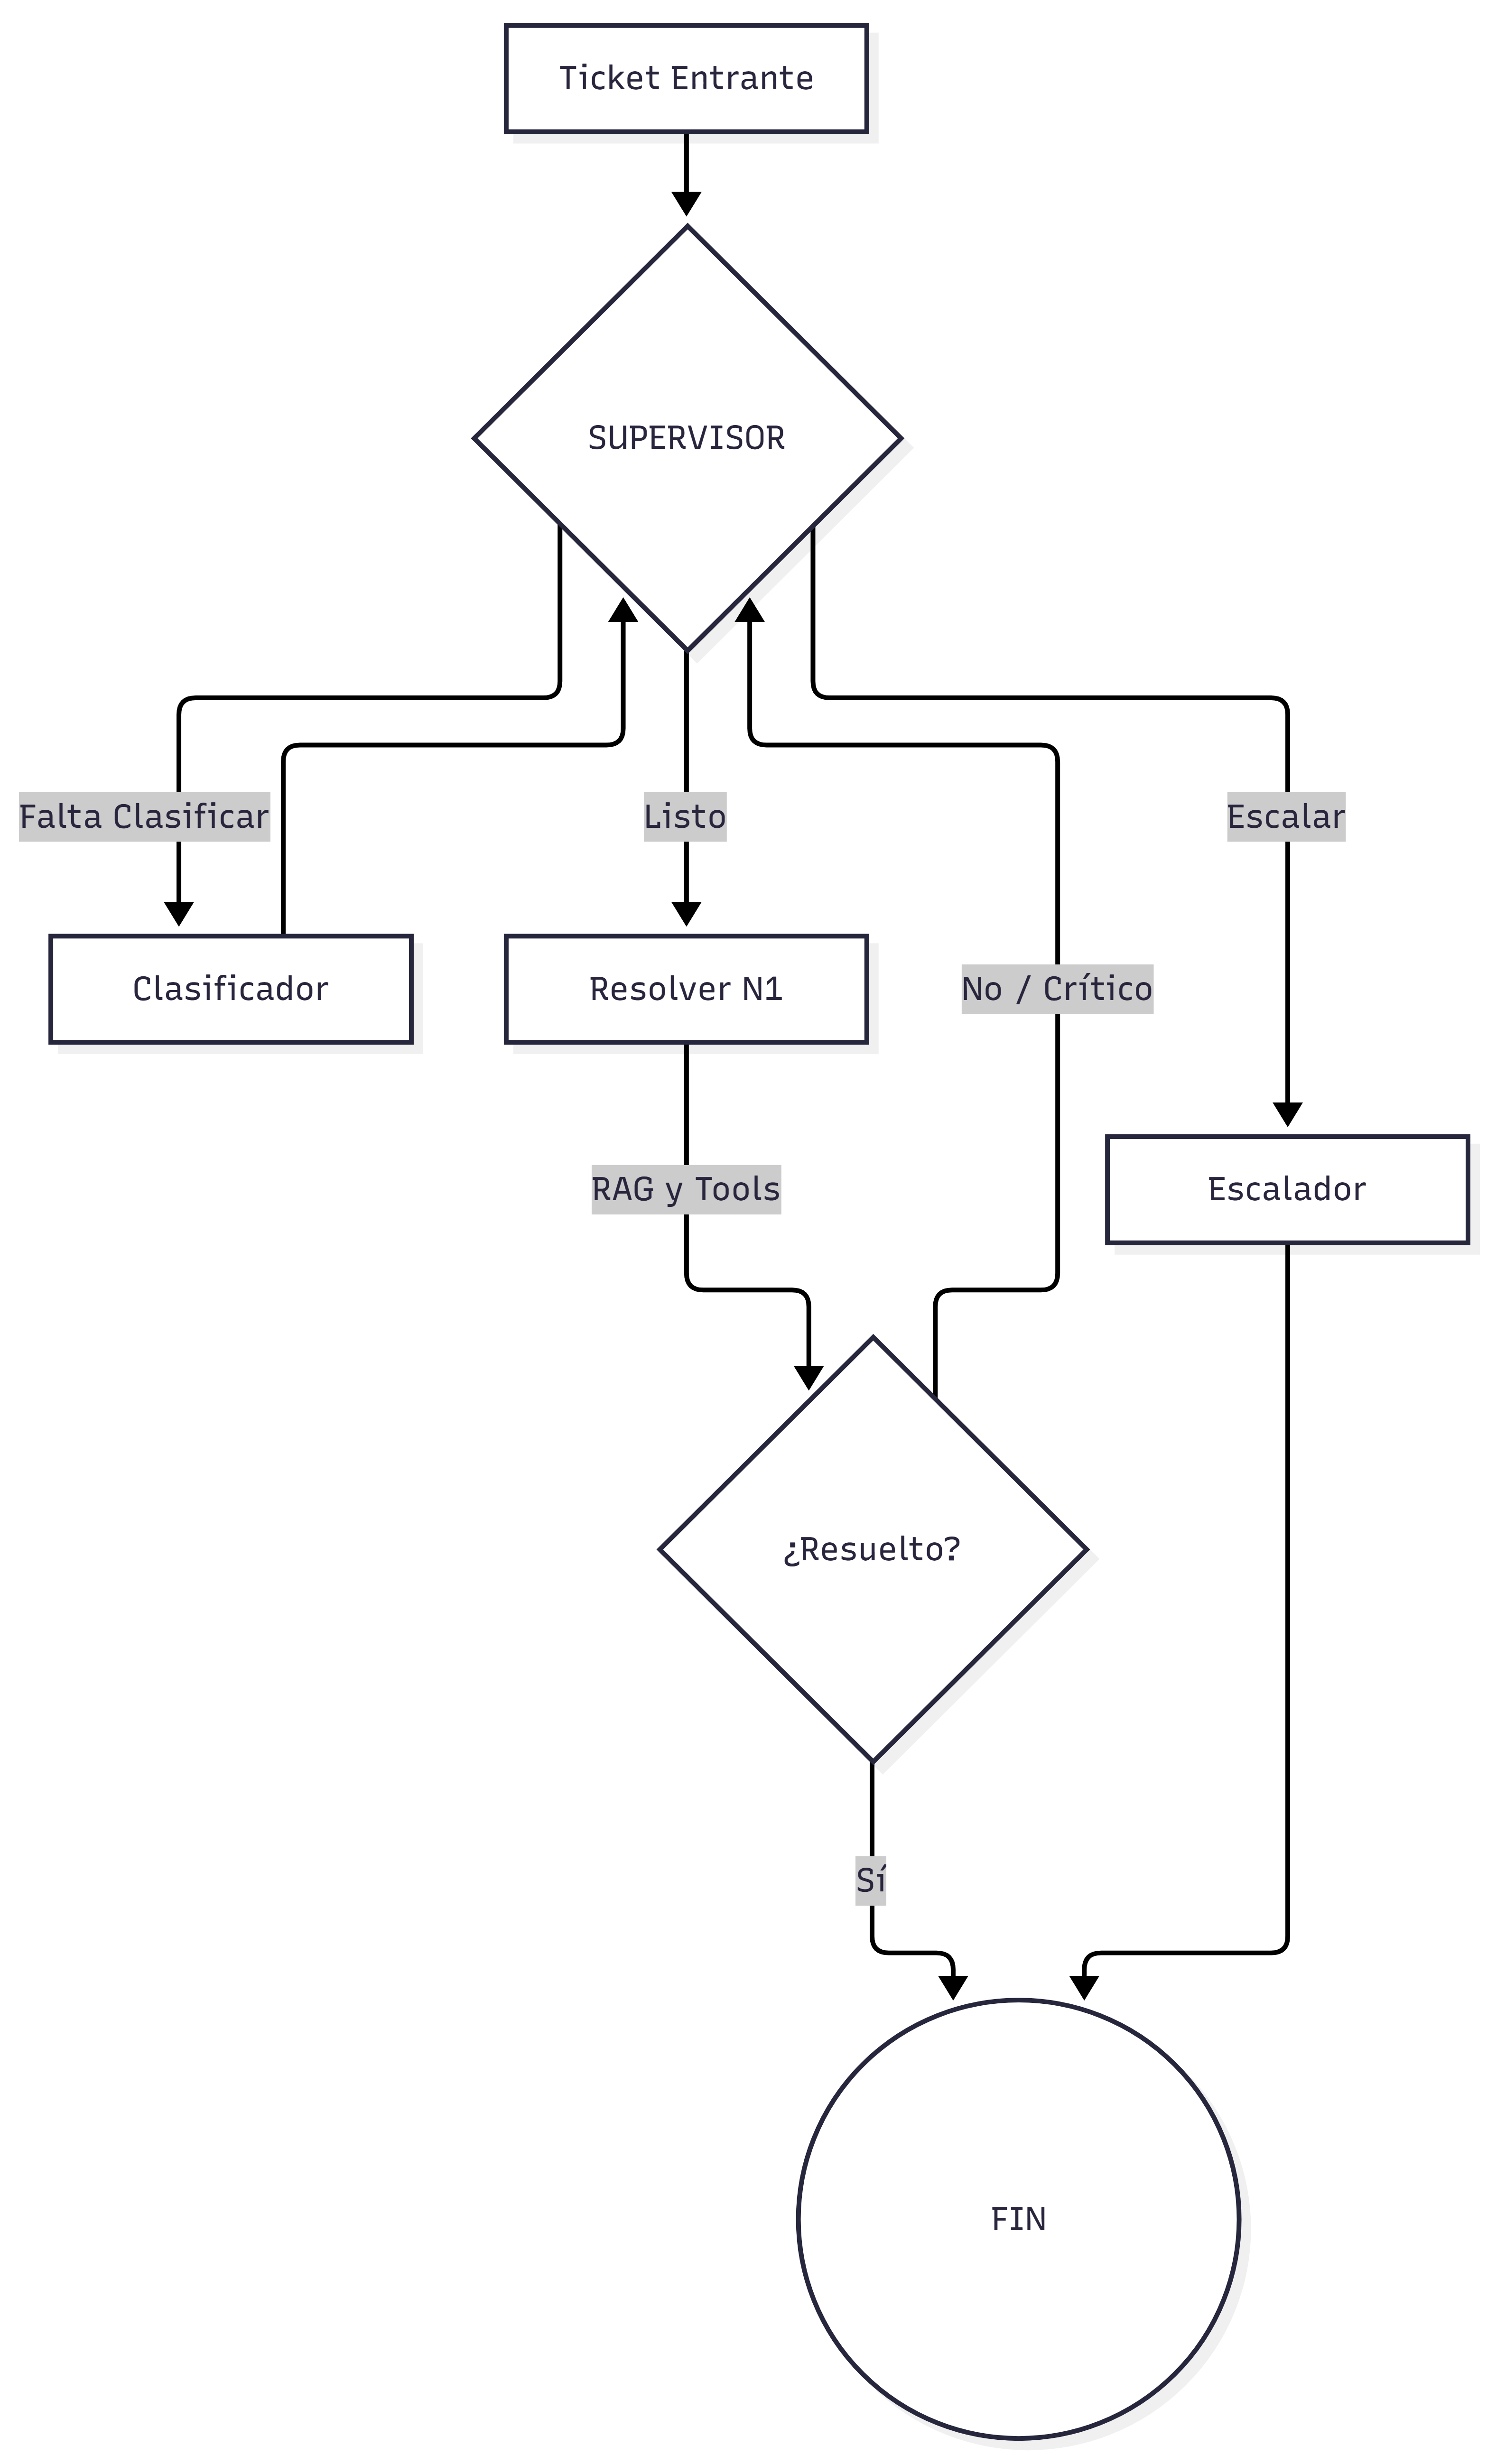

## Paso 1: Configuración del Entorno y Dependencias
En esta sección se prepara el entorno de ejecución en Google Colab. La **Celda 0** instala las librerías del agente (LangGraph, LangChain, ChromaDB, HuggingFace y Groq) con versiones compatibles entre sí; después de ejecutarla se debe **reiniciar la sesión** (*Entorno de ejecución → Reiniciar sesión*) y continuar desde la **Celda 1**, que carga la clave de API de Groq, el motor de razonamiento (LLM) del agente.

In [1]:
# Celda 0: Instalación de dependencias (solo Colab). Después de ejecutarla: Entorno de ejecución > Reiniciar sesión
!pip uninstall -y -q google-adk
!pip install -q -U langgraph langchain-core langchain-groq langchain-chroma langchain-huggingface sentence-transformers \
    opentelemetry-api opentelemetry-sdk opentelemetry-proto \
    opentelemetry-exporter-otlp-proto-common opentelemetry-exporter-otlp-proto-grpc

In [2]:
# Celda 1: Configuración de la API Key de GROQ
import os

# - En Colab: crear un secreto llamado 'GROQ_API' en el panel izquierdo (🔑)
# - Fuera de Colab: definir la variable de entorno GROQ_API antes de abrir el notebook
try:
    from google.colab import userdata
    os.environ["GROQ_API"] = userdata.get('GROQ_API')
    print("API Key de GROQ configurada correctamente (Colab Secrets).")
except Exception:
    if os.environ.get("GROQ_API"):
        print("API Key de GROQ tomada desde la variable de entorno GROQ_API.")
    else:
        print("⚠️ No se encontró la API Key. Configure el secreto/variable GROQ_API.")

API Key de GROQ configurada correctamente (Colab Secrets).


## Paso 2: Infraestructura de TechCorp y Herramientas (Tools)
En este bloque se simula el entorno organizacional de TechCorp SpA.
1. **Memoria a Largo Plazo (RAG):** Se configura una base de datos vectorial (ChromaDB) con los manuales de soporte técnico (KB). El agente también escribe en ella los incidentes que cierra.
2. **Herramientas de Consulta:** `consultar_cmdb` y `buscar_kb`.
3. **Herramientas de Escritura/Acción:** `crear_ticket`, `notificar_usuario`, `escalar_n2` y `registrar_incidente`.

In [3]:
# Celda 2: Infraestructura de TechCorp, Memoria de Largo Plazo (RAG) y Herramientas
from datetime import datetime
from langchain_core.tools import tool
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document

# --- 1. RAG: Base de Conocimiento de TechCorp (Memoria de Largo Plazo) ---
kb_techcorp = [
    Document(page_content="SOPORTE VPN: Para usuarios en Santiago, Valparaíso o Concepción. Error de conexión FortiClient. Solución: Reiniciar cliente, verificar expiración de contraseña AD. Si persiste, reinstalar versión 7.0.",
             metadata={"id": "KB-VPN", "tipo": "KB"}),
    Document(page_content="SOPORTE IMPRESORAS: Impresoras HP en piso 3. Atasco de papel: Abrir panel lateral derecho, retirar papel con cuidado. Error offline: Verificar cable de red o conexión WiFi 'TechCorp_Staff'.",
             metadata={"id": "KB-IMP", "tipo": "KB"}),
    Document(page_content="SOPORTE ACCESOS: Restablecimiento de contraseña Windows/AD. Se realiza vía portal self-service mi.techcorp.cl. Requiere validación de 2 pasos (MFA).",
             metadata={"id": "KB-ACC", "tipo": "KB"}),
    Document(page_content="SOPORTE HARDWARE: Equipos Lenovo ThinkPad asignados. Si el equipo no enciende, verificar cargador USB-C y mantener presionado el botón de encendido por 15 segundos.",
             metadata={"id": "KB-HW", "tipo": "KB"}),
]

print("Descargando modelo de embeddings gratuito (esto puede tomar un momento la primera vez)...")
embeddings_locales = HuggingFaceEmbeddings(
    model_name="intfloat/multilingual-e5-small",
    model_kwargs={'device': 'cpu'},  # Usa 'cuda' si tienes GPU en Colab
    encode_kwargs={'normalize_embeddings': True}
)
print("Modelo cargado.")

# Colección con nombre fijo: si la celda se re-ejecuta, se limpia en vez de duplicar documentos
vectorstore = Chroma(collection_name="techcorp_kb", embedding_function=embeddings_locales,
                     collection_metadata={"hnsw:space": "cosine"})  # relevancia = similitud coseno
try:
    vectorstore.reset_collection()
except Exception:
    pass
vectorstore.add_documents(kb_techcorp, ids=[d.metadata["id"] for d in kb_techcorp])

K_RESULTADOS = 2  # se recuperan 2 documentos: el LLM decide si alguno realmente aplica

# --- 2. CMDB Simulada (inventario de equipos) ---
cmdb_db = {
    "juan.perez":   "Lenovo ThinkPad T14, IP: 10.0.0.45, Sede: Santiago",
    "maria.gomez":  "Dell XPS 13, IP: 10.0.1.22, Sede: Valparaíso",
    "pedro.silva":  "MacBook Pro M2, IP: 10.0.2.10, Sede: Concepción",
    "ana.rojas":    "HP EliteBook 840, IP: 10.0.0.87, Sede: Santiago (piso 3)",
    "carlos.munoz": "Lenovo ThinkPad E14, IP: 10.0.0.91, Sede: Santiago (piso 3)",
}

# --- 3. Sistema de tickets simulado ---
SLA_POR_PRIORIDAD = {"Alta": "1 hora", "Media": "4 horas", "Baja": "24 horas"}
tickets_db = {}  # ticket_id -> datos del ticket (evidencia de escritura)

# --- 4. Herramientas (Tools) ---
@tool
def consultar_cmdb(usuario: str) -> str:
    """Consulta el equipo, IP y sede asignados a un usuario en TechCorp."""
    return cmdb_db.get(usuario, "Usuario no encontrado en CMDB.")

@tool
def buscar_kb(problema: str) -> str:
    """Busca soluciones en la base de conocimientos de TechCorp (manuales e incidentes históricos)."""
    resultados = vectorstore.similarity_search_with_relevance_scores(problema, k=K_RESULTADOS)
    if not resultados:
        return "No se encontró solución en la KB."
    lineas = []
    for doc, score in resultados:
        lineas.append(f"[{doc.metadata.get('id', '?')} | relevancia {score:.2f}] {doc.page_content}")
    return "\n".join(lineas)

@tool
def crear_ticket(ticket_id: str, descripcion: str, prioridad: str, usuario: str) -> str:
    """Crea un ticket en el sistema de Service Desk con la prioridad y SLA correspondientes."""
    sla = SLA_POR_PRIORIDAD.get(prioridad, "4 horas")
    tickets_db[ticket_id] = {"usuario": usuario, "prioridad": prioridad, "sla": sla,
                             "descripcion": descripcion, "estado": "abierto",
                             "creado": datetime.now().strftime("%H:%M:%S")}
    return f"Ticket {ticket_id} CREADO en Service Desk. Usuario: {usuario} | Prioridad: {prioridad} | SLA: {sla}"

@tool
def notificar_usuario(usuario: str, mensaje: str) -> str:
    """Envía un correo de notificación al usuario con la solución o el estado de su caso."""
    return f"Correo enviado a {usuario}@techcorp.cl: '{mensaje}'"

@tool
def escalar_n2(motivo: str, usuario: str) -> str:
    """Escala el ticket al equipo de ingeniería de Nivel 2 indicando el motivo técnico."""
    return f"CASO ESCALADO A N2. Usuario: {usuario}. Motivo: {motivo}"

@tool
def registrar_incidente(ticket_id: str, resumen: str) -> str:
    """Guarda el resultado de un ticket cerrado en la memoria de largo plazo (ChromaDB) para casos futuros."""
    doc_id = f"HIST-{ticket_id}"
    try:
        vectorstore.delete(ids=[doc_id])  # si el ticket se reabrió, se reemplaza su historial
    except Exception:
        pass
    vectorstore.add_documents(
        [Document(page_content=f"INCIDENTE HISTÓRICO {ticket_id}: {resumen}",
                  metadata={"id": doc_id, "tipo": "HISTORIAL"})],
        ids=[doc_id])
    return f"Incidente {ticket_id} registrado en la memoria de largo plazo."

tools = [consultar_cmdb, buscar_kb, crear_ticket, notificar_usuario, escalar_n2, registrar_incidente]
print(f"{len(tools)} herramientas de TechCorp y RAG configurados con embeddings gratuitos.")

Descargando modelo de embeddings gratuito (esto puede tomar un momento la primera vez)...


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Modelo cargado.
6 herramientas de TechCorp y RAG configurados con embeddings gratuitos.


## Paso 3: Definición de Sub-Agentes Especializados
En este bloque se definen los roles y responsabilidades de cada sub-agente del equipo de soporte:
- **Clasificador (LLM):** Determina categoría y prioridad.
- **Resolver N1 (LLM + herramientas):** Consulta la CMDB, crea el ticket, recupera contexto con RAG y el LLM elige la herramienta a ejecutar (`notificar_usuario` o `escalar_n2`).
- **Escalador (LLM + herramientas):** Resume el caso para N2, lo deriva y notifica al usuario.

*Nota de arquitectura:* Se define el estado compartido (`AgentState`) que actúa como memoria de corto plazo (IE3) para mantener el contexto durante el flujo y entre mensajes del mismo ticket.

In [4]:
# Celda 3: Definición del Estado y Sub-agentes (Groq)
import os
import re
import time
import operator
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langchain_groq import ChatGroq

PAUSA = 0.5  # pausa visual entre pasos para la demo en vivo

# --- FUNCIONES AUXILIARES ---
def extraer_texto(contenido):
    if isinstance(contenido, list):
        for bloque in contenido:
            if isinstance(bloque, dict) and bloque.get("type") == "text":
                return bloque.get("text", "")
        return str(contenido)
    return contenido

def ultimo_mensaje_usuario(state):
    humanos = [m for m in state["messages"] if isinstance(m, HumanMessage)]
    return humanos[-1].content if humanos else ""

# --- 1. ESTADO COMPARTIDO (Memoria de corto plazo, persistida por thread_id con MemorySaver) ---
class AgentState(TypedDict, total=False):
    messages: Annotated[list[BaseMessage], operator.add]  # historial acumulado de la conversación
    usuario: str
    ticket_id: str
    categoria: str
    prioridad: str
    clasificacion: str
    equipo: str
    estado_ticket: str        # abierto | requiere_escalar | resuelto | escalado_n2
    intentos_n1: int          # cuántas soluciones N1 se han entregado en este ticket
    solucion_aplicada: str
    motivo_escalamiento: str
    riesgo_fisico: bool
    ticket_creado: bool
    next_agent: str

# --- 2. INICIALIZACIÓN DEL LLM (GROQ) ---
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=os.environ.get("GROQ_API"),
    max_retries=5,  # reintentos automáticos ante límites de tasa del plan gratuito
)

# --- 3. SUB-AGENTE CLASIFICADOR ---
CATEGORIAS = ["VPN", "Hardware", "Accesos", "Impresoras", "Otros"]

def parsear_clasificacion(texto):
    """Extrae categoría y prioridad de la respuesta del LLM. Si no puede, usa valores seguros."""
    cat = re.search(r"Categor[ií]a\s*:\s*([A-Za-zÁÉÍÓÚáéíóú]+)", texto or "", re.IGNORECASE)
    pri = re.search(r"Prioridad\s*:\s*(Alta|Media|Baja)", texto or "", re.IGNORECASE)
    categoria = "Otros"
    if cat:
        for c in CATEGORIAS:
            if c.lower() == cat.group(1).lower():
                categoria = c
    prioridad = pri.group(1).capitalize() if pri else "Media"
    return categoria, prioridad

def clasificar(problema):
    prompt = SystemMessage(content=f"""Eres el Clasificador de la Mesa de Ayuda de TechCorp SpA.
Analiza el siguiente problema: '{problema}'.
Criterios de prioridad:
- Alta: el usuario no puede trabajar, o existe riesgo para la persona, el equipo o la seguridad.
- Media: el problema afecta parcialmente el trabajo y existe una alternativa temporal.
- Baja: solicitudes, instalaciones o consultas sin impacto inmediato.
Devuelve ÚNICAMENTE un string con el formato exacto:
'Categoria: <VPN/Hardware/Accesos/Impresoras/Otros> | Prioridad: <Alta/Media/Baja>'""")
    try:
        texto = extraer_texto(llm.invoke([prompt]).content)
    except Exception as e:
        print(f"   └─ ⚠️  Error del LLM al clasificar ({type(e).__name__}). Se usa clasificación por defecto.")
        texto = ""
    categoria, prioridad = parsear_clasificacion(texto)
    return categoria, prioridad, f"Categoria: {categoria} | Prioridad: {prioridad}"

def nodo_clasificador(state: AgentState):
    print("\n\033[96m╭─────────────────────────────────────────────────────────╮")
    print("│ 🧠 [CLASIFICADOR] Analizando la solicitud del usuario...│")
    print("╰─────────────────────────────────────────────────────────╯\033[0m")
    time.sleep(PAUSA)
    categoria, prioridad, texto = clasificar(state["messages"][0].content)
    print(f"   └─ 📋 Resultado: \033[93m{texto}\033[0m")
    return {"categoria": categoria, "prioridad": prioridad, "clasificacion": texto,
            "messages": [SystemMessage(content=f"[Clasificador]: {texto}")]}

# --- 4. REGLA DE SEGURIDAD (guardrail) ---
# Casos con riesgo físico NUNCA se resuelven en N1, sin importar lo que diga la KB o el LLM.
PALABRAS_RIESGO = ["humo", "fuego", "chispa", "quem", "incendi", "explot",
                   "descarga eléctrica", "batería hinchada", "derrame"]

def detectar_riesgo_fisico(texto):
    t = (texto or "").lower()
    return [p for p in PALABRAS_RIESGO if p in t]

# --- 5. SUB-AGENTE RESOLVER N1 ---
MAX_INTENTOS_N1 = 1  # política: si el usuario vuelve porque la solución N1 no funcionó, se escala

# El LLM recibe las herramientas de salida y ELIGE cuál ejecutar (decisión autónoma)
llm_resolver = llm.bind_tools([notificar_usuario, escalar_n2], tool_choice="any")  # "any": debe elegir una

PROMPT_RESOLVER = """Eres el agente Resolver N1 de la Mesa de Ayuda de TechCorp SpA.
Debes decidir UNA acción llamando exactamente a UNA herramienta:
- notificar_usuario: SOLO si la base de conocimientos contiene una solución que aplica al problema
  Y al equipo del usuario. El mensaje debe contener los pasos concretos de la KB, en español y cordial.
- escalar_n2: si la KB no contiene una solución aplicable, si la solución corresponde a otro modelo de
  equipo, si el problema requiere permisos, compras o instalaciones que N1 no puede realizar,
  o si existe riesgo para la persona o el equipo. Indica el motivo técnico en 'motivo'.
Nunca inventes soluciones que no estén en la base de conocimientos."""

def nodo_resolver(state: AgentState):
    print("\n\033[92m╭─────────────────────────────────────────────────────────╮")
    print("│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │")
    print("╰─────────────────────────────────────────────────────────╯\033[0m")
    time.sleep(PAUSA)

    usuario = state["usuario"]
    ticket_id = state["ticket_id"]
    problema = state["messages"][0].content
    prioridad = state.get("prioridad", "Media")
    intentos = state.get("intentos_n1", 0)
    cambios = {}

    # 1. Consulta de contexto: equipo del usuario
    print("   └─ ⚙️  Consultando CMDB...")
    equipo = consultar_cmdb.invoke({"usuario": usuario})
    print(f"      Equipo: {equipo}")
    cambios["equipo"] = equipo

    # 2. Escritura: se crea el ticket una sola vez, con la prioridad real del Clasificador
    if not state.get("ticket_creado"):
        print("   └─ ⚙️  Creando ticket en Service Desk...")
        print("      " + crear_ticket.invoke({"ticket_id": ticket_id, "descripcion": problema,
                                               "prioridad": prioridad, "usuario": usuario}))
        cambios["ticket_creado"] = True
    time.sleep(PAUSA)

    # 3. Seguimiento: el usuario volvió al mismo ticket (memoria de corto plazo)
    if intentos >= MAX_INTENTOS_N1:
        nuevo = ultimo_mensaje_usuario(state)
        print(f"   └─ 🧠 Memoria: este ticket ya recibió {intentos} solución(es) N1.")
        print(f"      Solución anterior: {state.get('solucion_aplicada', '')[:120]}...")
        print(f"      Nuevo mensaje: '{nuevo}'")
        print("   └─ ⚠️  La solución N1 no funcionó. Se requiere escalar.")
        motivo = (f"Seguimiento del ticket: la solución N1 entregada no resolvió el problema. "
                  f"Nuevo mensaje del usuario: '{nuevo}'.")
        return {**cambios, "estado_ticket": "requiere_escalar", "motivo_escalamiento": motivo,
                "messages": [SystemMessage(content=f"[Resolver]: {motivo}")]}

    # 4. Regla de seguridad (no depende del LLM)
    riesgo = detectar_riesgo_fisico(problema)
    if riesgo:
        print(f"   └─ 🔥 Riesgo físico detectado ({', '.join(riesgo)}). No se intenta solución N1.")
        motivo = f"Riesgo físico reportado por el usuario ({', '.join(riesgo)}). Requiere revisión presencial."
        if prioridad != "Alta":  # el riesgo físico eleva la prioridad del ticket
            print(f"   └─ ⬆️  Prioridad elevada: {prioridad} → Alta")
            tickets_db.get(ticket_id, {}).update({"prioridad": "Alta", "sla": SLA_POR_PRIORIDAD["Alta"]})
        return {**cambios, "estado_ticket": "requiere_escalar", "motivo_escalamiento": motivo,
                "riesgo_fisico": True, "prioridad": "Alta",
                "messages": [SystemMessage(content=f"[Resolver]: {motivo}")]}

    # 5. Recuperación semántica (RAG): KB + incidentes históricos
    print("   └─ ⚙️  Buscando en la Base de Conocimientos (RAG)...")
    contexto_kb = buscar_kb.invoke({"problema": problema})
    for linea in contexto_kb.split("\n"):
        print(f"      {linea[:110]}...")
    time.sleep(PAUSA)

    # 6. Razonamiento: el LLM decide qué herramienta ejecutar
    print("   └─ 🤔 El LLM evalúa si la solución aplica al usuario y su equipo...")
    mensajes = [SystemMessage(content=PROMPT_RESOLVER),
                HumanMessage(content=(f"Usuario: {usuario}\nEquipo asignado (CMDB): {equipo}\n"
                                      f"Clasificación: {state.get('clasificacion', '')}\n"
                                      f"Problema: {problema}\n\n"
                                      f"Resultados de la base de conocimientos:\n{contexto_kb}"))]
    try:
        tool_calls = llm_resolver.invoke(mensajes).tool_calls
    except Exception as e:
        print(f"   └─ ⚠️  Error del LLM ({type(e).__name__}).")
        tool_calls = []

    if not tool_calls:
        motivo = "El agente no pudo determinar una solución con confianza; por seguridad se escala."
        print(f"   └─ ⚠️  {motivo}")
        return {**cambios, "estado_ticket": "requiere_escalar", "motivo_escalamiento": motivo,
                "messages": [SystemMessage(content=f"[Resolver]: {motivo}")]}

    llamada = tool_calls[0]
    args = dict(llamada.get("args", {}))
    print(f"   └─ 🎯 Decisión del LLM: \033[93m{llamada['name']}\033[0m")

    if llamada["name"] == "notificar_usuario":
        args["usuario"] = usuario
        args.setdefault("mensaje", "Revisa la solución publicada en la base de conocimientos.")
        print("      " + notificar_usuario.invoke(args))
        registrar_incidente.invoke({"ticket_id": ticket_id, "resumen": (
            f"Usuario {usuario} ({equipo}). Problema: {problema} "
            f"Resultado: RESUELTO en N1. Solución entregada: {args['mensaje']}")})
        tickets_db.get(ticket_id, {})["estado"] = "resuelto"
        return {**cambios, "estado_ticket": "resuelto", "intentos_n1": intentos + 1,
                "solucion_aplicada": args["mensaje"],
                "messages": [SystemMessage(content=f"[Resolver]: Solución enviada: {args['mensaje']}")]}

    # El LLM eligió escalar_n2: el Escalador ejecuta la derivación
    motivo = args.get("motivo") or "La base de conocimientos no tiene una solución aplicable."
    print(f"      Motivo: {motivo}")
    return {**cambios, "estado_ticket": "requiere_escalar", "motivo_escalamiento": motivo,
            "messages": [SystemMessage(content=f"[Resolver]: Se requiere escalar. {motivo}")]}

# --- 6. SUB-AGENTE ESCALADOR ---
def generar_resumen_n2(state):
    """El LLM redacta un resumen técnico para N2 usando todo el historial del ticket."""
    historial = "\n".join(m.content for m in state["messages"])
    prompt = SystemMessage(content=(
        "Eres el Escalador de la Mesa de Ayuda de TechCorp. Redacta en máximo 3 líneas un resumen "
        "técnico para el equipo de Nivel 2: problema, equipo afectado, acciones ya realizadas por N1 "
        f"y motivo del escalamiento.\n\nEquipo: {state.get('equipo', '')}\n"
        f"Motivo: {state.get('motivo_escalamiento', '')}\nHistorial del ticket:\n{historial}"))
    try:
        return extraer_texto(llm.invoke([prompt]).content).strip()
    except Exception:
        return state.get("motivo_escalamiento", "Requiere revisión especializada.")

def nodo_escalador(state: AgentState):
    print("\n\033[91m╭─────────────────────────────────────────────────────────╮")
    print("│ 🚨 [ESCALADOR] Derivando caso a Ingeniería Nivel 2      │")
    print("╰─────────────────────────────────────────────────────────╯\033[0m")
    time.sleep(PAUSA)

    usuario = state["usuario"]
    ticket_id = state["ticket_id"]
    prioridad = state.get("prioridad", "Media")
    sla = SLA_POR_PRIORIDAD.get(prioridad, "4 horas")

    print("   └─ 🤔 Generando resumen técnico para N2 con el historial del ticket...")
    resumen = generar_resumen_n2(state)
    print("   └─ ⚙️  Escalando a Nivel 2...")
    print("      " + escalar_n2.invoke({"motivo": resumen, "usuario": usuario}))
    time.sleep(PAUSA)

    mensaje = (f"Tu caso {ticket_id} fue escalado a Ingeniería Nivel 2 con prioridad {prioridad}. "
               f"Un especialista te contactará dentro de {sla}.")
    if state.get("riesgo_fisico"):
        mensaje += " Por seguridad, desconecta el equipo de la corriente y no lo vuelvas a encender."
    print("   └─ ⚙️  Notificando al usuario...")
    print("      " + notificar_usuario.invoke({"usuario": usuario, "mensaje": mensaje}))

    registrar_incidente.invoke({"ticket_id": ticket_id, "resumen": (
        f"Usuario {usuario} ({state.get('equipo', '')}). Problema: {state['messages'][0].content} "
        f"Resultado: ESCALADO a N2. Motivo: {state.get('motivo_escalamiento', '')}")})
    tickets_db.get(ticket_id, {})["estado"] = "escalado_n2"

    return {"estado_ticket": "escalado_n2",
            "messages": [SystemMessage(content=f"[Escalador]: Caso escalado a N2. {resumen}")]}

print("Estado compartido y sub-agentes definidos.")

Estado compartido y sub-agentes definidos.


## Paso 4: Orquestación del Flujo con LangGraph (El Supervisor)
Aquí se implementa el patrón de diseño **Supervisor**. Se construye un grafo de estados donde el nodo principal (Supervisor) evalúa constantemente el estado del ticket y toma decisiones adaptativas (decisiones de enrutamiento) para enviar la tarea al sub-agente correspondiente, garantizando que el flujo no se quede atascado y responda a las condiciones cambiantes.

In [5]:
# Celda 4: Construcción del Grafo Jerárquico (Supervisor)
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver

# 1. SUPERVISOR: decide el siguiente agente según el estado del ticket
def nodo_supervisor(state: AgentState):
    print("\n\033[95m👔 [SUPERVISOR] Evaluando el estado actual del ticket...\033[0m")
    time.sleep(PAUSA)
    estado = state.get("estado_ticket", "abierto")

    if estado == "resuelto":
        print("   └─ Decisión: Ticket solucionado en N1. ✅ FIN DEL FLUJO.")
        return {"next_agent": END}
    elif estado == "escalado_n2":
        print("   └─ Decisión: Ticket derivado a N2. 🚨 FIN DEL FLUJO.")
        return {"next_agent": END}
    elif not state.get("clasificacion"):
        print("   └─ Decisión: Falta clasificación. ➡️  Enviando a CLASIFICADOR.")
        return {"next_agent": "clasificador"}
    elif estado == "requiere_escalar":
        print("   └─ Decisión: Requiere especialista. ➡️  Enviando a ESCALADOR.")
        return {"next_agent": "escalador"}
    else:
        if state.get("intentos_n1", 0) > 0:
            print(f"   └─ 🧠 Memoria del ticket: {len(state['messages'])} mensajes en el historial | "
                  f"{state['clasificacion']} | intentos N1: {state['intentos_n1']}")
        print("   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.")
        return {"next_agent": "resolver"}

# 2. Construcción del Grafo
workflow = StateGraph(AgentState)
workflow.add_node("supervisor", nodo_supervisor)
workflow.add_node("clasificador", nodo_clasificador)
workflow.add_node("resolver", nodo_resolver)
workflow.add_node("escalador", nodo_escalador)
workflow.set_entry_point("supervisor")

# 3. Aristas condicionales: el Supervisor enruta según 'next_agent'
workflow.add_conditional_edges(
    "supervisor",
    lambda state: state["next_agent"],
    {"clasificador": "clasificador", "resolver": "resolver", "escalador": "escalador", END: END}
)

# 4. Después de cada sub-agente, el control vuelve al Supervisor
workflow.add_edge("clasificador", "supervisor")
workflow.add_edge("resolver", "supervisor")
workflow.add_edge("escalador", "supervisor")

# 5. Compilación con memoria de corto plazo persistente por thread_id (= ID del ticket)
memory = MemorySaver()
app = workflow.compile(checkpointer=memory)
print("\n ¡Arquitectura Multi-Agente de TechCorp compilada exitosamente!")


 ¡Arquitectura Multi-Agente de TechCorp compilada exitosamente!


## Paso 5: Simulación y Demo en Vivo
En esta sección se ponen a prueba las capacidades del agente con tres escenarios que recorren caminos distintos del grafo:

| Escenario | Qué demuestra | Indicador |
|---|---|---|
| **A. Cola de tickets** | Planificación por prioridad y tres decisiones distintas: resolver con la KB, escalar por riesgo físico y escalar por falta de conocimiento | IE1, IE5, IE7 |
| **B. Seguimiento del mismo ticket** | Continuidad: el agente recuerda el caso sin volver a clasificarlo y escala porque la solución no funcionó | IE3 |
| **C. Ticket similar a uno cerrado** | El RAG recupera el manual y el incidente histórico que el agente guardó | IE4 |

In [6]:
# Celda 5: Simulador de Mesa de Ayuda (funciones de la demo)
from IPython.display import display, HTML
from langchain_core.messages import HumanMessage

resultados_demo = []  # evidencia de pruebas: (escenario, ticket, esperado, obtenido)

def simular_ticket(usuario, problema, thread_id, triage=None):
    """Envía un mensaje al agente. Si el thread_id ya existe, el agente recupera su memoria."""
    previo = app.get_state({"configurable": {"thread_id": thread_id}}).values
    titulo = "🔁 SEGUIMIENTO DE TICKET EXISTENTE" if previo else "🎫 NUEVO TICKET INGRESADO"
    display(HTML(f"""
    <div style="border: 2px solid #4A90E2; border-radius: 8px; padding: 15px; background-color: #f8f9fa; margin-bottom: 10px; color: #333333; font-family: 'Segoe UI', Arial, sans-serif; box-shadow: 0 2px 5px rgba(0,0,0,0.1);">
        <h3 style="color: #4A90E2; margin-top: 0; border-bottom: 1px solid #ddd; padding-bottom: 8px;">{titulo}</h3>
        <p style="margin: 5px 0;"><b>👤 Solicitante:</b> {usuario}@techcorp.cl</p>
        <p style="margin: 5px 0;"><b>💻 ID de Caso:</b> {thread_id}</p>
        <p style="margin: 5px 0;"><b>📝 Mensaje:</b> <i>"{problema}"</i></p>
    </div>
    """))

    config = {"configurable": {"thread_id": thread_id}, "recursion_limit": 20}
    inputs = {"messages": [HumanMessage(content=problema)], "usuario": usuario,
              "ticket_id": thread_id, "estado_ticket": "abierto"}
    if triage:  # clasificación ya hecha por el planificador de la cola
        inputs.update({"categoria": triage["categoria"], "prioridad": triage["prioridad"],
                       "clasificacion": triage["clasificacion"]})

    print("\n🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...")
    print("=" * 60)
    for _ in app.stream(inputs, config=config):
        pass  # los prints están dentro de los nodos
    print("\n" + "=" * 60)
    print("🏁 FLUJO COMPLETADO. Revisando estado final del Grafo...")

    final = app.get_state(config).values
    estado = final.get("estado_ticket", "desconocido")
    color = "#28a745" if estado == "resuelto" else "#dc3545" if estado == "escalado_n2" else "#d39e00"
    icono = "✅" if estado == "resuelto" else "🚨" if estado == "escalado_n2" else "⏳"
    display(HTML(f"""
    <div style="border-left: 5px solid {color}; padding: 12px; background-color: #f8f9fa; margin-top: 15px; margin-bottom: 30px; font-family: 'Segoe UI', Arial, sans-serif; color: #333333; box-shadow: 0 2px 5px rgba(0,0,0,0.1);">
        <h4 style="color: {color}; margin: 0;">{icono} ESTADO FINAL DEL TICKET {thread_id}: {estado.upper()}</h4>
        <p style="margin: 6px 0 0 0;">{final.get('clasificacion', '')} | Mensajes en memoria: {len(final.get('messages', []))}</p>
    </div>
    """))
    return final

ORDEN_PRIORIDAD = {"Alta": 0, "Media": 1, "Baja": 2}

def procesar_cola(cola):
    """Planificador: clasifica todos los tickets entrantes, los ordena por prioridad y los atiende en ese orden."""
    print("📥 PLANIFICADOR: triage de la cola de tickets entrantes...\n")
    planificados = []
    for t in cola:
        categoria, prioridad, texto = clasificar(t["problema"])
        if detectar_riesgo_fisico(t["problema"]):
            prioridad, texto = "Alta", f"Categoria: {categoria} | Prioridad: Alta"
        planificados.append({**t, "categoria": categoria, "prioridad": prioridad, "clasificacion": texto})
        print(f"   {t['thread_id']} (llegada #{len(planificados)}) → {texto}")

    planificados.sort(key=lambda t: ORDEN_PRIORIDAD.get(t["prioridad"], 1))  # orden estable
    filas = "".join(
        f"<tr><td>{i}</td><td>{t['thread_id']}</td><td>{t['usuario']}</td><td>{t['categoria']}</td>"
        f"<td><b>{t['prioridad']}</b></td><td>{SLA_POR_PRIORIDAD[t['prioridad']]}</td></tr>"
        for i, t in enumerate(planificados, 1))
    display(HTML(f"""
    <div style="font-family: 'Segoe UI', Arial, sans-serif; color: #333333; background-color: #f8f9fa; padding: 12px; border-radius: 8px;">
    <h4 style="margin-top: 0;">📋 Plan de atención (ordenado por prioridad)</h4>
    <table style="border-collapse: collapse;" border="1" cellpadding="6">
    <tr><th>Orden</th><th>Ticket</th><th>Usuario</th><th>Categoría</th><th>Prioridad</th><th>SLA</th></tr>{filas}
    </table></div>"""))

    finales = {}
    for t in planificados:
        finales[t["thread_id"]] = simular_ticket(t["usuario"], t["problema"], t["thread_id"], triage=t)
    return planificados, finales

print("Simulador listo.")

Simulador listo.


In [7]:
# Celda 6: ESCENARIO A — Cola de tickets: planificación por prioridad y decisiones adaptativas
cola_entrante = [  # orden de llegada (NO es el orden de atención)
    {"usuario": "pedro.silva", "thread_id": "TCK-1003",
     "problema": "Necesito que me instalen una licencia de AutoCAD para un proyecto nuevo."},
    {"usuario": "ana.rojas", "thread_id": "TCK-1004",
     "problema": "La impresora HP del piso 3 aparece offline y no puedo imprimir."},
    {"usuario": "juan.perez", "thread_id": "TCK-1001",
     "problema": "Hola, estoy en la oficina de Santiago y no me puedo conectar a la VPN, me da error FortiClient."},
    {"usuario": "maria.gomez", "thread_id": "TCK-1002",
     "problema": "Mi notebook Dell no enciende, la pantalla está negra y ayer salió humo de la parte trasera."},
]

plan, finales_A = procesar_cola(cola_entrante)

esperados_A = {"TCK-1001": "resuelto", "TCK-1002": "escalado_n2",
               "TCK-1003": "escalado_n2", "TCK-1004": "resuelto"}
for tid, esperado in esperados_A.items():
    resultados_demo.append(("A - Cola por prioridad", tid, esperado, finales_A[tid].get("estado_ticket")))

📥 PLANIFICADOR: triage de la cola de tickets entrantes...

   TCK-1003 (llegada #1) → Categoria: Otros | Prioridad: Baja
   TCK-1004 (llegada #2) → Categoria: Impresoras | Prioridad: Media
   TCK-1001 (llegada #3) → Categoria: VPN | Prioridad: Alta
   TCK-1002 (llegada #4) → Categoria: Hardware | Prioridad: Alta


Orden,Ticket,Usuario,Categoría,Prioridad,SLA
1,TCK-1001,juan.perez,VPN,Alta,1 hora
2,TCK-1002,maria.gomez,Hardware,Alta,1 hora
3,TCK-1004,ana.rojas,Impresoras,Media,4 horas
4,TCK-1003,pedro.silva,Otros,Baja,24 horas



🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.

╭─────────────────────────────────────────────────────────╮
│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │
╰─────────────────────────────────────────────────────────╯
   └─ ⚙️  Consultando CMDB...
      Equipo: Lenovo ThinkPad T14, IP: 10.0.0.45, Sede: Santiago
   └─ ⚙️  Creando ticket en Service Desk...
      Ticket TCK-1001 CREADO en Service Desk. Usuario: juan.perez | Prioridad: Alta | SLA: 1 hora
   └─ ⚙️  Buscando en la Base de Conocimientos (RAG)...
      [KB-VPN | relevancia 0.93] SOPORTE VPN: Para usuarios en Santiago, Valparaíso o Concepción. Error de conexión ...
      [KB-ACC | relevancia 0.86] SOPORTE ACCESOS: Restablecimiento de contraseña Windows/AD. Se realiza vía portal s...
   └─ 🤔 El LLM evalúa si la solución aplica al usuario y su equipo...
   └─ 🎯 Decisión del LLM: notificar_usuario
      Cor


🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.

╭─────────────────────────────────────────────────────────╮
│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │
╰─────────────────────────────────────────────────────────╯
   └─ ⚙️  Consultando CMDB...
      Equipo: Dell XPS 13, IP: 10.0.1.22, Sede: Valparaíso
   └─ ⚙️  Creando ticket en Service Desk...
      Ticket TCK-1002 CREADO en Service Desk. Usuario: maria.gomez | Prioridad: Alta | SLA: 1 hora
   └─ 🔥 Riesgo físico detectado (humo). No se intenta solución N1.

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Requiere especialista. ➡️  Enviando a ESCALADOR.

╭─────────────────────────────────────────────────────────╮
│ 🚨 [ESCALADOR] Derivando caso a Ingeniería Nivel 2      │
╰─────────────────────────────────────────────────────────╯
   └─ 🤔 Generando resumen técnico para N2 con el histor


🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.

╭─────────────────────────────────────────────────────────╮
│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │
╰─────────────────────────────────────────────────────────╯
   └─ ⚙️  Consultando CMDB...
      Equipo: HP EliteBook 840, IP: 10.0.0.87, Sede: Santiago (piso 3)
   └─ ⚙️  Creando ticket en Service Desk...
      Ticket TCK-1004 CREADO en Service Desk. Usuario: ana.rojas | Prioridad: Media | SLA: 4 horas
   └─ ⚙️  Buscando en la Base de Conocimientos (RAG)...
      [KB-IMP | relevancia 0.89] SOPORTE IMPRESORAS: Impresoras HP en piso 3. Atasco de papel: Abrir panel lateral d...
      [HIST-TCK-1002 | relevancia 0.82] INCIDENTE HISTÓRICO TCK-1002: Usuario maria.gomez (Dell XPS 13, IP: 10.0.1.2...
   └─ 🤔 El LLM evalúa si la solución aplica al usuario y su equipo...
   └─ 🎯 Decisión del LLM: notificar_usuario
  


🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.

╭─────────────────────────────────────────────────────────╮
│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │
╰─────────────────────────────────────────────────────────╯
   └─ ⚙️  Consultando CMDB...
      Equipo: MacBook Pro M2, IP: 10.0.2.10, Sede: Concepción
   └─ ⚙️  Creando ticket en Service Desk...
      Ticket TCK-1003 CREADO en Service Desk. Usuario: pedro.silva | Prioridad: Baja | SLA: 24 horas
   └─ ⚙️  Buscando en la Base de Conocimientos (RAG)...
      [KB-ACC | relevancia 0.85] SOPORTE ACCESOS: Restablecimiento de contraseña Windows/AD. Se realiza vía portal s...
      [HIST-TCK-1002 | relevancia 0.82] INCIDENTE HISTÓRICO TCK-1002: Usuario maria.gomez (Dell XPS 13, IP: 10.0.1.2...
   └─ 🤔 El LLM evalúa si la solución aplica al usuario y su equipo...
   └─ 🎯 Decisión del LLM: escalar_n2
      Motivo: In

In [8]:
# Celda 7: ESCENARIO B — Continuidad: el usuario vuelve al MISMO ticket (memoria de corto plazo)
# Se usa el mismo thread_id (TCK-1001). El agente recupera la clasificación, la solución
# entregada y el historial desde MemorySaver, sin volver a clasificar.
final_B = simular_ticket(
    usuario="juan.perez",
    problema="Reinicié FortiClient y revisé mi contraseña como me indicaron, pero la VPN sigue sin conectar.",
    thread_id="TCK-1001",
)
resultados_demo.append(("B - Seguimiento (memoria corto plazo)", "TCK-1001", "escalado_n2",
                        final_B.get("estado_ticket")))


🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ 🧠 Memoria del ticket: 3 mensajes en el historial | Categoria: VPN | Prioridad: Alta | intentos N1: 1
   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.

╭─────────────────────────────────────────────────────────╮
│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │
╰─────────────────────────────────────────────────────────╯
   └─ ⚙️  Consultando CMDB...
      Equipo: Lenovo ThinkPad T14, IP: 10.0.0.45, Sede: Santiago
   └─ 🧠 Memoria: este ticket ya recibió 1 solución(es) N1.
      Solución anterior: Hola Juan,

Para resolver el error de FortiClient al intentar conectarte a la VPN, sigue estos pasos:
1. Cierra FortiCli...
      Nuevo mensaje: 'Reinicié FortiClient y revisé mi contraseña como me indicaron, pero la VPN sigue sin conectar.'
   └─ ⚠️  La solución N1 no funcionó. Se requiere escalar.

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisi

In [9]:
# Celda 8: ESCENARIO C — Ticket nuevo similar a uno ya cerrado (memoria de largo plazo)
# El RAG recupera tanto el manual (KB) como el incidente histórico TCK-1004 guardado en ChromaDB.
print("🔎 Memoria de largo plazo antes del ticket (incidentes guardados por el agente):")
for d in vectorstore.get(where={"tipo": "HISTORIAL"})["documents"]:
    print("   •", d[:140], "...")

final_C = simular_ticket(
    usuario="carlos.munoz",
    problema="La impresora del piso 3 dice offline, no me deja imprimir nada.",
    thread_id="TCK-1005",
)
resultados_demo.append(("C - Historial (memoria largo plazo)", "TCK-1005", "resuelto",
                        final_C.get("estado_ticket")))

🔎 Memoria de largo plazo antes del ticket (incidentes guardados por el agente):
   • INCIDENTE HISTÓRICO TCK-1002: Usuario maria.gomez (Dell XPS 13, IP: 10.0.1.22, Sede: Valparaíso). Problema: Mi notebook Dell no enciende, la ...
   • INCIDENTE HISTÓRICO TCK-1004: Usuario ana.rojas (HP EliteBook 840, IP: 10.0.0.87, Sede: Santiago (piso 3)). Problema: La impresora HP del pi ...
   • INCIDENTE HISTÓRICO TCK-1003: Usuario pedro.silva (MacBook Pro M2, IP: 10.0.2.10, Sede: Concepción). Problema: Necesito que me instalen una  ...
   • INCIDENTE HISTÓRICO TCK-1001: Usuario juan.perez (Lenovo ThinkPad T14, IP: 10.0.0.45, Sede: Santiago). Problema: Hola, estoy en la oficina d ...



🚀 INICIANDO FLUJO DE TRABAJO AUTÓNOMO...

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Falta clasificación. ➡️  Enviando a CLASIFICADOR.

╭─────────────────────────────────────────────────────────╮
│ 🧠 [CLASIFICADOR] Analizando la solicitud del usuario...│
╰─────────────────────────────────────────────────────────╯
   └─ 📋 Resultado: Categoria: Impresoras | Prioridad: Media

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Clasificación lista. ➡️  Enviando a RESOLVER.

╭─────────────────────────────────────────────────────────╮
│ 🛠️  [RESOLVER N1] Buscando solución y ejecutando acciones │
╰─────────────────────────────────────────────────────────╯
   └─ ⚙️  Consultando CMDB...
      Equipo: Lenovo ThinkPad E14, IP: 10.0.0.91, Sede: Santiago (piso 3)
   └─ ⚙️  Creando ticket en Service Desk...
      Ticket TCK-1005 CREADO en Service Desk. Usuario: carlos.munoz | Prioridad: Media | SLA: 4 horas
   └─ ⚙️  Buscando en la Base de Conocimien

## Paso 6: Pruebas de Software
Pruebas unitarias de las herramientas, el parser de clasificación, la regla de seguridad y el enrutamiento del Supervisor, seguidas de la comparación entre el resultado esperado y el obtenido en cada escenario de la demo.

In [10]:
# Celda 9: Pruebas de software (evidencia)
import pandas as pd

# --- 1. Pruebas unitarias (deterministas, no usan el LLM) ---
assert parsear_clasificacion("Categoria: VPN | Prioridad: Alta") == ("VPN", "Alta")
assert parsear_clasificacion("categoría: hardware | prioridad: baja") == ("Hardware", "Baja")
assert parsear_clasificacion("respuesta inválida") == ("Otros", "Media")      # valor seguro
assert detectar_riesgo_fisico("salió humo del cargador") == ["humo"]
assert detectar_riesgo_fisico("no conecta la VPN") == []
assert "Dell XPS 13" in consultar_cmdb.invoke({"usuario": "maria.gomez"})
assert consultar_cmdb.invoke({"usuario": "no.existe"}) == "Usuario no encontrado en CMDB."
assert "KB-VPN" in buscar_kb.invoke({"problema": "error de conexión VPN FortiClient"})
assert "SLA: 1 hora" in crear_ticket.invoke({"ticket_id": "TEST-1", "descripcion": "prueba",
                                             "prioridad": "Alta", "usuario": "test"})
tickets_db.pop("TEST-1", None)

# El Supervisor termina el flujo en ambos estados finales (sin loop infinito)
assert nodo_supervisor({"estado_ticket": "resuelto", "messages": []})["next_agent"] == END
assert nodo_supervisor({"estado_ticket": "escalado_n2", "messages": []})["next_agent"] == END
assert nodo_supervisor({"estado_ticket": "requiere_escalar", "clasificacion": "x",
                        "messages": []})["next_agent"] == "escalador"
print("\n✅ Pruebas unitarias: 12/12 OK")

# --- 2. Pruebas de integración: resultado esperado vs. obtenido en la demo ---
df = pd.DataFrame(resultados_demo, columns=["Escenario", "Ticket", "Esperado", "Obtenido"])
df["OK"] = (df["Esperado"] == df["Obtenido"]).map({True: "✅", False: "❌"})
display(df)
print(f"Pruebas de integración: {(df['OK'] == '✅').sum()}/{len(df)} OK")

# --- 3. Estado final del sistema de tickets (evidencia de escritura) ---
display(pd.DataFrame.from_dict(tickets_db, orient="index")[["usuario", "prioridad", "sla", "estado", "creado"]])


👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Ticket solucionado en N1. ✅ FIN DEL FLUJO.

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Ticket derivado a N2. 🚨 FIN DEL FLUJO.

👔 [SUPERVISOR] Evaluando el estado actual del ticket...
   └─ Decisión: Requiere especialista. ➡️  Enviando a ESCALADOR.

✅ Pruebas unitarias: 12/12 OK


,Escenario,Ticket,Esperado,Obtenido,OK
0,A - Cola por prioridad,TCK-1001,resuelto,resuelto,✅
1,A - Cola por prioridad,TCK-1002,escalado_n2,escalado_n2,✅
2,A - Cola por prioridad,TCK-1003,escalado_n2,escalado_n2,✅
3,A - Cola por prioridad,TCK-1004,resuelto,resuelto,✅
4,B - Seguimiento (memoria corto plazo),TCK-1001,escalado_n2,escalado_n2,✅
5,C - Historial (memoria largo plazo),TCK-1005,resuelto,resuelto,✅


Pruebas de integración: 6/6 OK


,usuario,prioridad,sla,estado,creado
TCK-1001,juan.perez,Alta,1 hora,escalado_n2,23:23:43
TCK-1002,maria.gomez,Alta,1 hora,escalado_n2,23:23:47
TCK-1004,ana.rojas,Media,4 horas,resuelto,23:23:51
TCK-1003,pedro.silva,Baja,24 horas,escalado_n2,23:23:55
TCK-1005,carlos.munoz,Media,4 horas,resuelto,23:24:07


# Referencias (APA 7)

Chroma. (s.f.). *Chroma documentation*. https://docs.trychroma.com/

Groq. (2024). *Groq API Documentation*. https://console.groq.com/docs

Hugging Face. (s.f.). *intfloat/multilingual-e5-small* [Modelo de embeddings]. https://huggingface.co/intfloat/multilingual-e5-small

LangChain, Inc. (2024). *LangChain Documentation*. https://python.langchain.com/

LangGraph. (2024). *LangGraph Documentation*. https://langchain-ai.github.io/langgraph/

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474.

OpenAI. (2025). *gpt-oss-120b & gpt-oss-20b model card*. arXiv. https://arxiv.org/abs/2508.10925

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing* (pp. 3982–3992). Association for Computational Linguistics.

Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). *Multilingual E5 text embeddings: A technical report*. arXiv. https://arxiv.org/abs/2402.05672

### Uso de Inteligencia Artificial

Anthropic. (2026). *Claude* (versión Opus 5.5) [Modelo de lenguaje de gran tamaño]. https://claude.ai

DeepSeek. (2026). *DeepSeek* [Modelo de lenguaje de gran tamaño]. https://chat.deepseek.com